In [16]:
from pathlib import Path

from skald import combine_runs
import seaborn as sns
import polars as pl

import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator
import numpy as np

from experiments.visualizations import set_paper_style

set_paper_style()

In [3]:
metrics = combine_runs(
    directory=Path(r"W:\EndlessWM\experiments\reports\covariate_vs_concept"), include_params=["data.name", "data.dataset_seed"]
).filter(name="mAP")
metrics

2026-06-30 14:30:11.215 | INFO     | skald:combine_runs:463 - 🔎 found 9 skald runs in W:\EndlessWM\experiments\reports\covariate_vs_concept.


Output()

name,value,stream,step,epoch,task,pattern,data.name,data.dataset_seed
str,f64,str,i64,i64,i64,str,str,i32
"""mAP""",0.3235,"""present""",null,0,0,"""*""","""iii-as-con""",1
"""mAP""",0.3034,"""present""",null,1,0,"""*""","""iii-as-con""",1
"""mAP""",0.2963,"""present""",null,2,0,"""*""","""iii-as-con""",1
"""mAP""",0.2922,"""present""",null,3,0,"""*""","""iii-as-con""",1
"""mAP""",0.2736,"""present""",null,4,0,"""*""","""iii-as-con""",1
…,…,…,…,…,…,…,…,…
"""mAP""",1.0,"""train""",null,null,20,"""center_donut""","""iii-as-cov""",3
"""mAP""",1.0,"""train""",null,null,20,"""border_donut""","""iii-as-cov""",3
"""mAP""",1.0,"""train""",null,null,20,"""edge_ring""","""iii-as-cov""",3


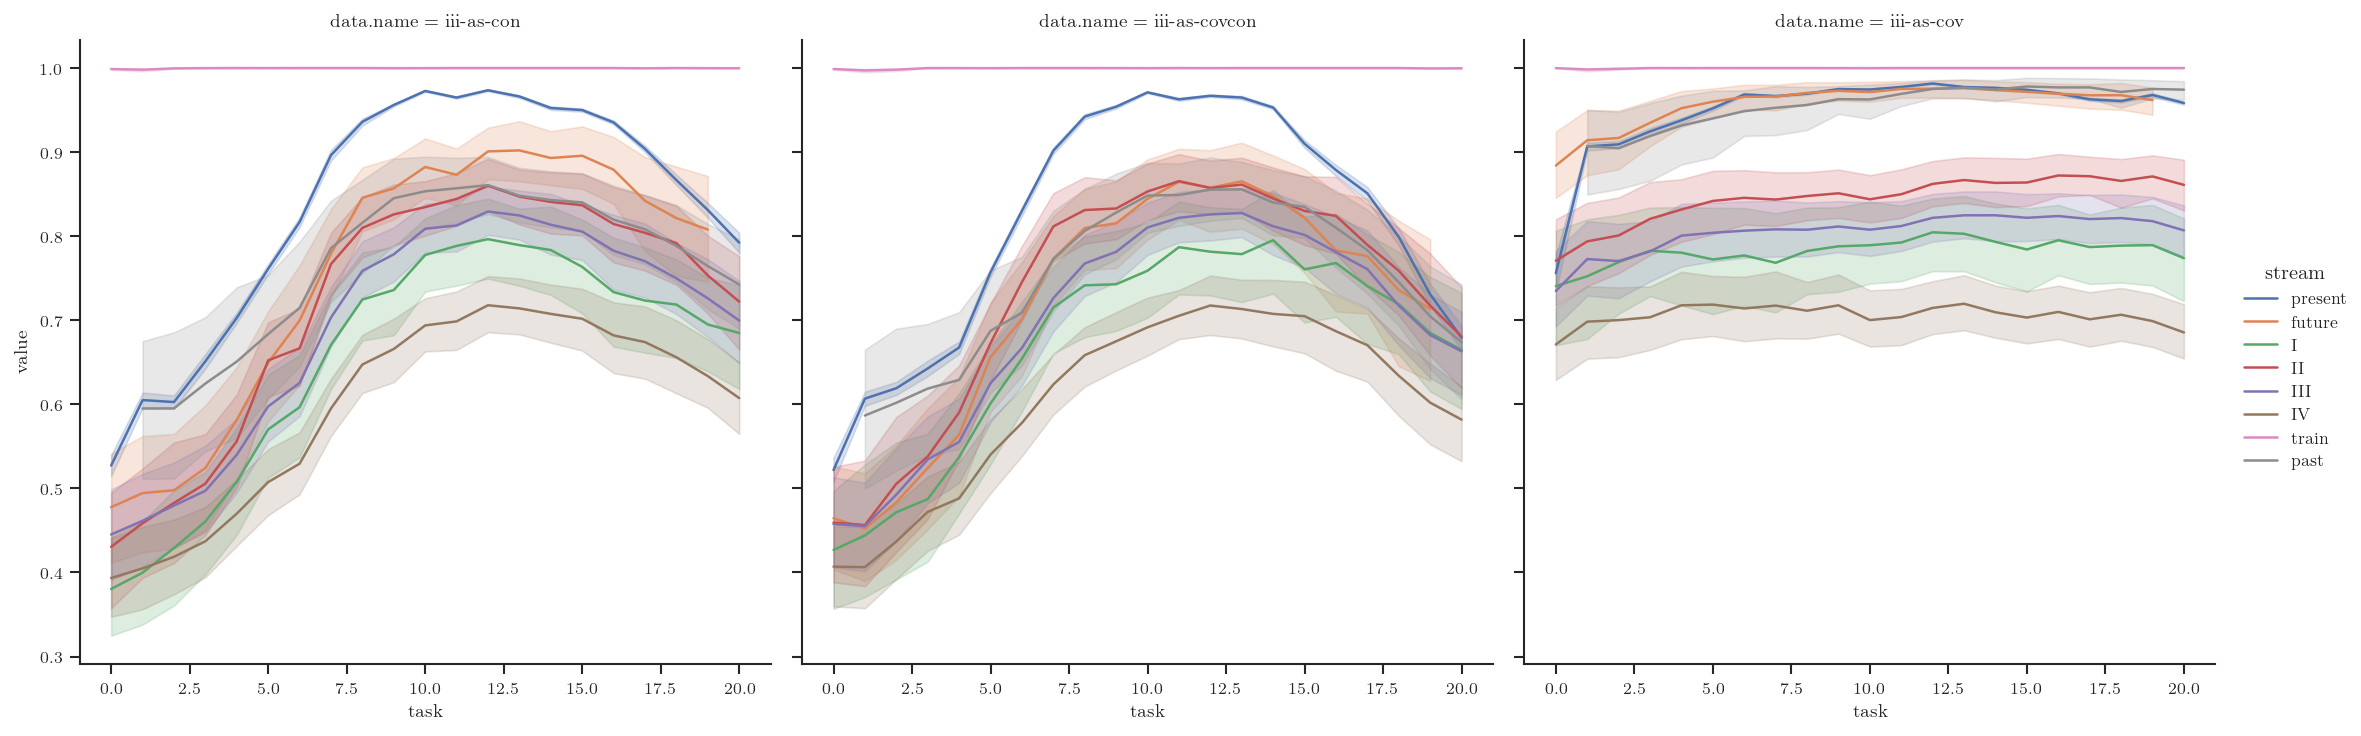

In [9]:
fig = sns.relplot(
    metrics,
    x="task",
    y="value",
    hue="stream",
    col="data.name",
    kind="line",
    legend="full",
    facet_kws={"sharex": False},
)
fig

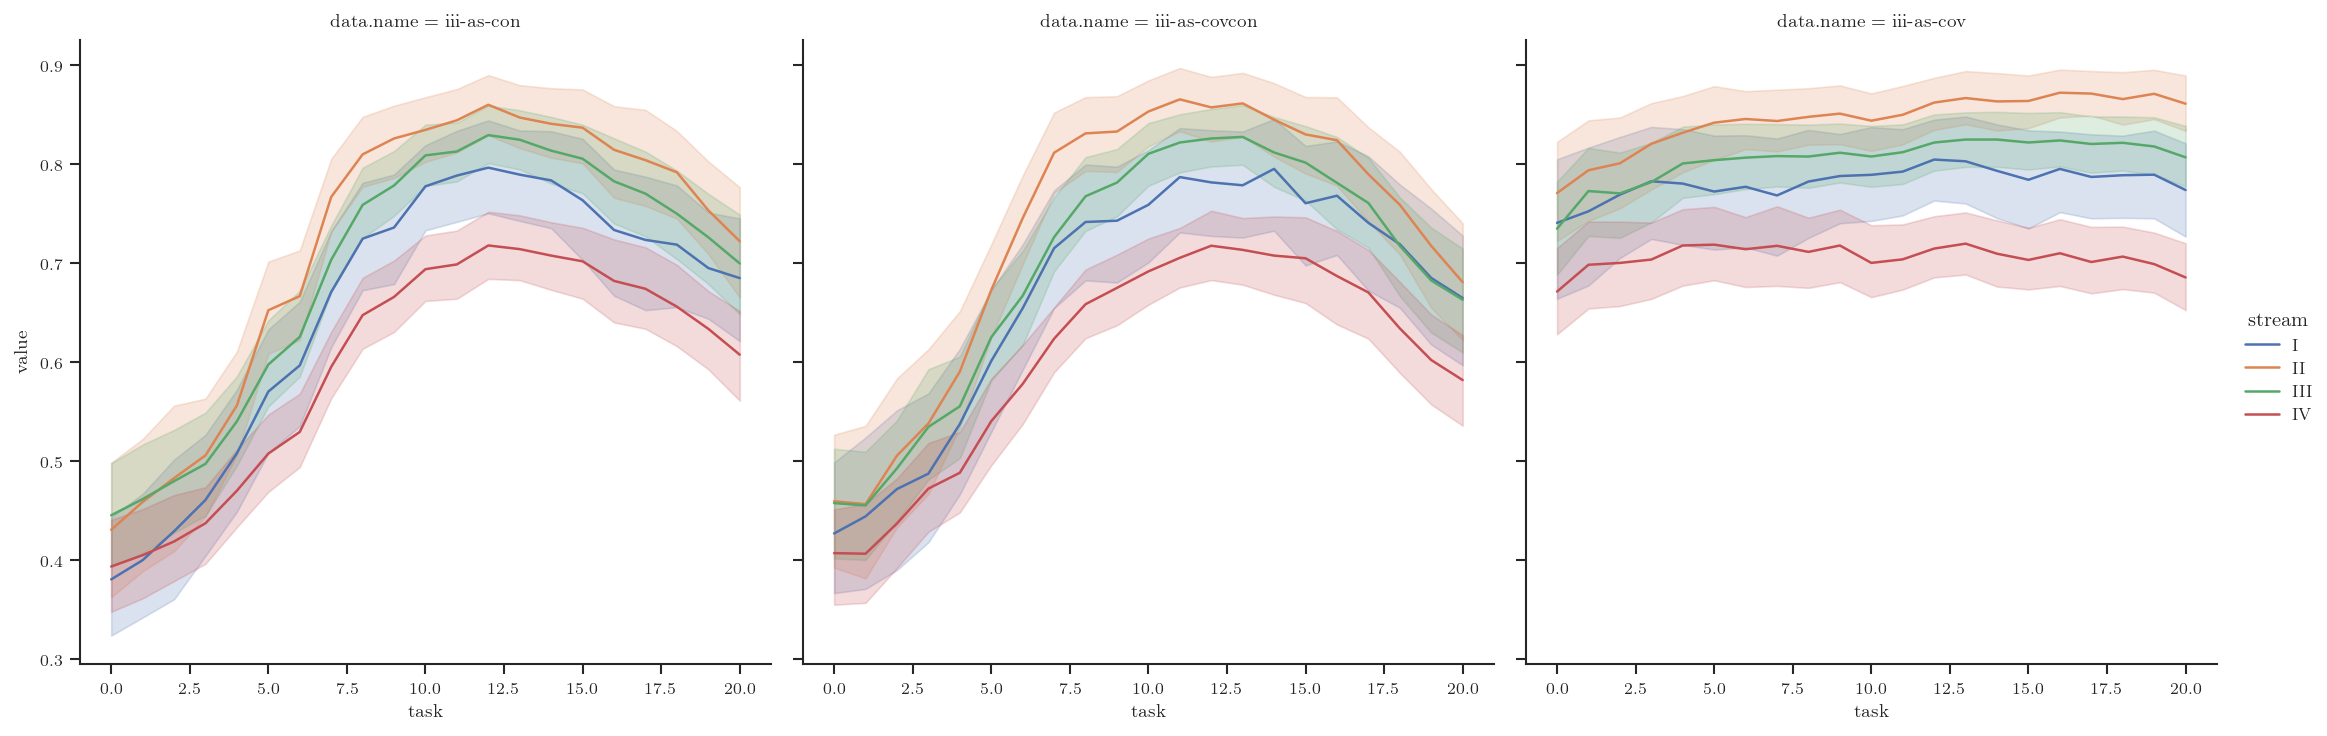

In [10]:
fig = sns.relplot(
    metrics.filter(pl.col("stream").is_in(["I", "II", "III", "IV"])),
    x="task",
    y="value",
    hue="stream",
    col="data.name",
    kind="line",
    legend="full",
    facet_kws={"sharex": False},
)
fig

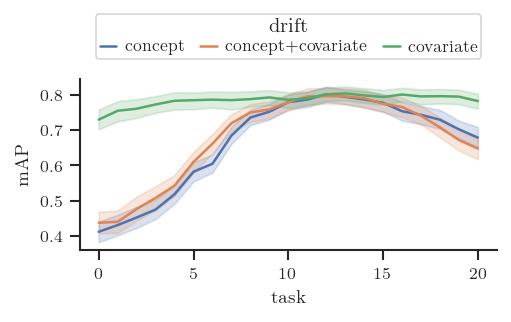

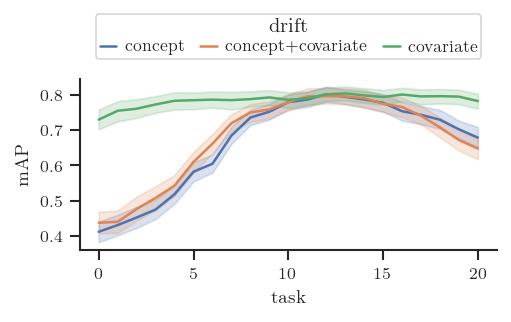

In [ ]:
fig, ax = plt.subplots(figsize=(3.5, 2.25))

ax = sns.lineplot(
    metrics.filter(pl.col("epoch").is_null(), pl.col("stream").is_in(["I", "II", "III", "IV"])).with_columns(
        pl.col("data.name").replace({"iii-as-con": "concept", "iii-as-covcon": "concept+covariate", "iii-as-cov": "covariate"})
    ),
    x="task",
    y="value",
    hue="data.name",
    legend="full",
    ax=ax,
)
ax.set(
    ylabel="mAP",
)

sns.move_legend(
    ax,
    "lower center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.02),
    title="drift",
    frameon=True,
    borderaxespad=1.0,
    borderpad=0.25,
    handlelength=1.0,
    handletextpad=0.5,
    columnspacing=1.0,
    labelspacing=0.2,
)

fig.tight_layout()

fig

In [22]:
fig.savefig("../../reports/concept_vs_covariate_drift/concept_vs_covariate_drift.pdf", bbox_inches="tight", dpi=300)
fig.savefig("../../reports/concept_vs_covariate_drift/concept_vs_covariate_drift.png", bbox_inches="tight", dpi=300)